In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import ctREFPROP.ctREFPROP as ct

import matplotlib.patches as mpatches
from matplotlib.patches import Patch, Rectangle
from scipy.interpolate import interp1d

# Set up paths - explicitly point to REFPROP directory since we're running from THESIS/PLOTTING
base_path = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/refprop1/REFPROP"

USE_LOCAL_SEITZ = False

seitz_path = os.path.join(os.path.dirname(os.path.abspath("__file__")), "seitzCode") if USE_LOCAL_SEITZ else base_path
if seitz_path not in sys.path:
    sys.path.insert(0, seitz_path)
from SeitzModel import SeitzModel
print(f"SeitzModel loaded from: {seitz_path}")

lib_path = os.path.join(os.path.dirname(base_path), "REFPROP-cmake", "build", "librefprop.dylib")
fluids_path = base_path

RP = ct.REFPROPFunctionLibrary(lib_path)
RP.SETPATHdll(fluids_path)
print(f"REFPROP Version: {RP.RPVersion()}")
print(f"Library: {lib_path}\nFLUIDS: {fluids_path}")

SeitzModel loaded from: /Users/austindestcroix/Desktop/school_holders/projects/sbc/refprop1/REFPROP
REFPROP Version: 10.0.0.02
Library: /Users/austindestcroix/Desktop/school_holders/projects/sbc/refprop1/REFPROP-cmake/build/librefprop.dylib
FLUIDS: /Users/austindestcroix/Desktop/school_holders/projects/sbc/refprop1/REFPROP


In [30]:
## Style setup — PDEStyle colors + larger fonts
import PDEStyle as PS
ms = PS.MyStyleSet()
ms.SetMPLcolors()   # sets matplotlib prop_cycle to PDEStyle colors

plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 11,
})

In [35]:
# Compute Rc vs Q for Ar, Xe, CF4, C3F8 by sweeping temperature at fixed pressure
bar_to_psia = 14.5038

fluids_cfg = {
    'Argon': {'refprop': 'ARGON', 'color': ms.GetNextColor()},
    'Xenon': {'refprop': 'XENON', 'color': ms.GetNextColor()},
    'CF4':   {'refprop': 'R14',   'color': ms.GetNextColor()},
    'C3F8':  {'refprop': 'R218',  'color': ms.GetNextColor()},
}

P_bar = 10.0
P_psia = P_bar * bar_to_psia
P_kPa  = P_bar * 100.0

seitz_results = {}

for name, cfg in fluids_cfg.items():
    fluid_str = cfg['refprop']

    RP.SETUPdll(1, fluid_str, "HMX.BNC", "DEF")
    finfo = RP.INFOdll(1)
    T_crit_K = finfo.Tc

    # Saturation temperature at operating pressure
    satp = RP.SATPdll(P_kPa, [1.0], 1)
    if satp.ierr != 0:
        print(f"{name}: SATPdll failed (ierr={satp.ierr}), skipping")
        continue
    T_sat_K = satp.T

    # Sweep T from T_sat to T_crit; log-space in (T_crit-T) for better Q coverage
    dT_max = T_crit_K - T_sat_K - 1.0
    delta_T = np.logspace(np.log10(0.5), np.log10(dT_max), 100)[::-1]  # T_sat→T_crit order
    delta_T = np.linspace(0.5, dT_max, 100)[::-1]  # T_sat→T_crit order --- IGNORE ---
    T_K_arr = T_crit_K - delta_T
    T_C_arr = T_K_arr - 273.15

    Qs, Rcs = [], []
    for T_C in T_C_arr:
        try:
            res = SeitzModel(P_psia, T_C, Fluid=fluid_str)
            if (res is not None
                    and np.isfinite(res.Q) and np.isfinite(res.Rc)
                    and res.Q > 0 and res.Rc > 0):
                Qs.append(res.Q)
                Rcs.append(res.Rc)
        except Exception:
            pass

    seitz_results[name] = {
        'Q':    np.array(Qs),
        'Rc':   np.array(Rcs),
        'color': cfg['color'],
    }
    print(f"{name:6s}: {len(Qs):3d} pts | Q=[{min(Qs):.3f}, {max(Qs):.3f}] keV | Rc=[{min(Rcs):.2f}, {max(Rcs):.2f}] nm")

Argon :  63 pts | Q=[0.014, 1410.818] keV | Rc=[2.08, 195.33] nm
Xenon :  65 pts | Q=[0.027, 35376.651] keV | Rc=[2.41, 574.10] nm
CF4   :  62 pts | Q=[0.022, 2800.446] keV | Rc=[2.50, 239.71] nm
C3F8  :  57 pts | Q=[0.048, 3575.294] keV | Rc=[3.63, 260.15] nm


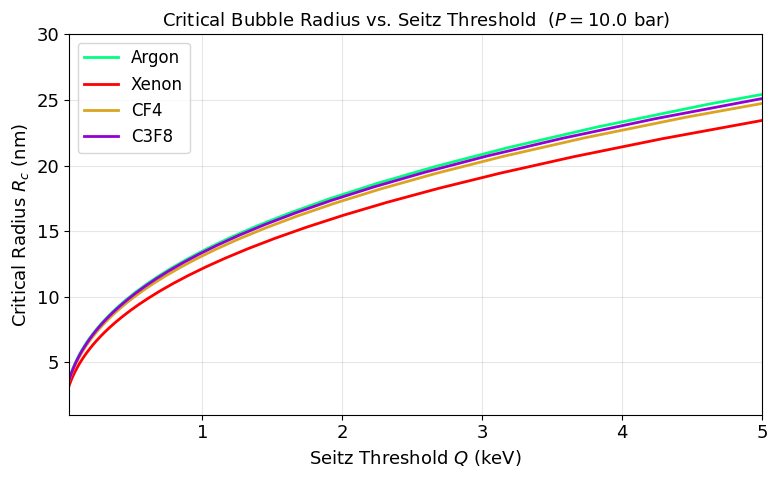

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))

for name, data in seitz_results.items():
    ax.plot(data['Q'], data['Rc'], color=data['color'], label=name, lw=2)

# ax.set_xscale('log')
# ax.set_yscale('log')
ax.set_xlim(0.05, 5)         # 50 eV – 5 keV
ax.set_ylim(1, 30)
ax.set_xlabel("Seitz Threshold $Q$ (keV)", fontsize=13)
ax.set_ylabel("Critical Radius $R_c$ (nm)", fontsize=13)
ax.set_title(f"Critical Bubble Radius vs. Seitz Threshold  ($P = {P_bar}$ bar)", fontsize=13)
ax.legend(fontsize=12)
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
from scipy.interpolate import RegularGridInterpolator

# --- Q and Rc grid for fixed-threshold bubble plot ---
# Mirrors the Argon operating space from phaseSpaceV2
# fluid_bubble  = "ARGON"
# n_grid_b      = 50
# T_K_range_b   = np.linspace(90, 135, n_grid_b)
# P_bar_range_b = np.linspace(0.5, 20,  n_grid_b)
# bar_to_psia_b = 14.50377

fluid_bubble  = "R14"  # CF4
n_grid_b      = 50
T_K_range_b   = np.linspace(150, 200, n_grid_b)
P_bar_range_b = np.linspace(0.5, 20,  n_grid_b)
bar_to_psia_b = 14.50377

T_K_grid_b, P_bar_grid_b = np.meshgrid(T_K_range_b, P_bar_range_b)
Q_grid_b  = np.full_like(T_K_grid_b, np.nan)
Rc_grid_b = np.full_like(T_K_grid_b, np.nan)

# Saturation curve for the chosen fluid
RP.SETUPdll(1, fluid_bubble, "HMX.BNC", "DEF")
_info_b = RP.INFOdll(1)
_Tsat_b = np.linspace(_info_b.Ttrp + 0.01, _info_b.Tc - 0.01, 300)
_Psat_b = np.array([RP.SATTdll(T, [1.0], 1).P for T in _Tsat_b]) / 100  # bar
_sat_b  = interp1d(_Tsat_b, _Psat_b, bounds_error=False, fill_value=np.nan)
Psat_at_T_b = _sat_b(T_K_range_b)

print(f"Computing {n_grid_b}×{n_grid_b} grid for {fluid_bubble}  "
      f"({T_K_range_b[0]:.0f}–{T_K_range_b[-1]:.0f} K,  "
      f"{P_bar_range_b[0]:.1f}–{P_bar_range_b[-1]:.1f} bar) ...")

valid_b = 0
for i, P_b in enumerate(P_bar_range_b):
    P_psia_b = P_b * bar_to_psia_b
    for j, T_b in enumerate(T_K_range_b):
        if not np.isnan(Psat_at_T_b[j]) and P_b < Psat_at_T_b[j]:
            try:
                r = SeitzModel(P_psia_b, T_b - 273.15, Fluid=fluid_bubble)
                if r is not None and r.Q is not None and r.Rc is not None:
                    Q_grid_b[i, j]  = r.Q
                    Rc_grid_b[i, j] = r.Rc
                    valid_b += 1
            except Exception:
                pass

# Interpolator for Rc at arbitrary (P, T) — axes must match meshgrid order
Rc_interp_b = RegularGridInterpolator(
    (P_bar_range_b, T_K_range_b), Rc_grid_b,
    method='linear', bounds_error=False, fill_value=np.nan
)
print(f"Done. {valid_b} valid points.  "
      f"Rc: {np.nanmin(Rc_grid_b):.1f}–{np.nanmax(Rc_grid_b):.1f} nm  |  "
      f"Q:  {np.nanmin(Q_grid_b)*1e3:.1f}–{np.nanmax(Q_grid_b)*1e3:.0f} eV")

Computing 50×50 grid for R14  (150–200 K,  0.5–20.0 bar) ...
Done. 790 valid points.  Rc: 4.5–9914.0 nm  |  Q:  76.9–94540749225 eV


threshold 0.1 keV bubble sizes: [25.03940838 25.03939083 25.0391892  25.03911925 25.03886477 25.03867754
 25.03843135 25.03828032 25.03824826 25.03811158] 

over T, P range: 200.0 198.43347875943095 2.157911489540466 0.5 

threshold 0.25 keV bubble sizes: [25.21997698 25.21821192 25.21614177 25.21415582 25.21255726 25.21069479
 25.20874527 25.20724626 25.20575713 25.20415751] 

over T, P range: 200.0 192.763333590734 6.4998429839085246 0.5 

threshold 0.5 keV bubble sizes: [25.41317096 25.40826554 25.40360782 25.39855681 25.39371622 25.38902418
 25.38449553 25.37953199 25.37499278 25.37127983] 

over T, P range: 200.0 188.42248500119354 8.718895376331835 0.5 

threshold 1.0 keV bubble sizes: [25.6752982  25.66453166 25.6531026  25.64264155 25.63138741 25.62048056
 25.61166707 25.60274191 25.59343471 25.58450771] 

over T, P range: 200.0 184.06161931239507 10.34449921294172 0.5 

threshold 5.0 keV bubble sizes: [26.70015312 26.65354383 26.60155849 26.55611641 26.51448316 26.46528213
 26

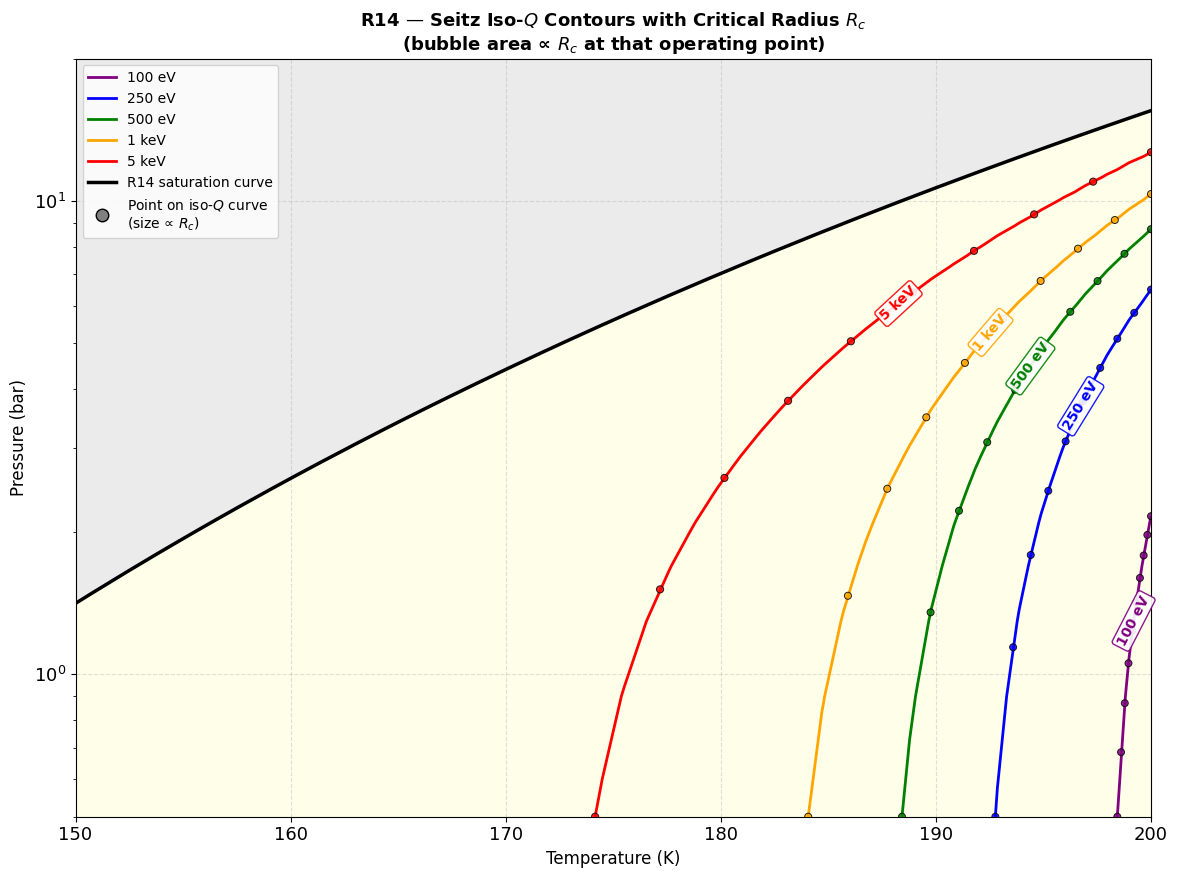

In [40]:
def sample_arc(seg, n=10):
    """Sample n equally-arc-length-spaced points along a 2-D contour segment."""
    ds = np.sqrt(np.sum(np.diff(seg, axis=0)**2, axis=1))
    s  = np.concatenate([[0], np.cumsum(ds)])
    su = np.linspace(0, s[-1], n)
    return np.interp(su, s, seg[:, 0]), np.interp(su, s, seg[:, 1])

threshold_keV_b    = [0.1,    0.25,   0.5,    1.0,     5.0  ]
threshold_labels_b = ['100 eV','250 eV','500 eV','1 keV','5 keV']
threshold_colors_b = ['purple','blue',  'green', 'orange','red' ]

# Rc → matplotlib marker area  (area ∝ Rc so larger bubble = larger critical radius)
_Rc_lo, _Rc_hi = np.nanmin(Rc_grid_b), np.nanmax(Rc_grid_b)
def rc_to_size(Rc, s_min=25, s_max=700):
    f = (np.clip(Rc, _Rc_lo, None) - _Rc_lo) / (_Rc_hi - _Rc_lo + 1e-15)
    return s_min + f * (s_max - s_min)

T_hires_b = np.linspace(T_K_range_b[0], _info_b.Tc, 500)
P_hires_b = _sat_b(T_hires_b)

fig, ax = plt.subplots(figsize=(12, 9))

ax.fill_between(T_hires_b, P_hires_b, P_bar_range_b[-1],
                color='lightgray',   alpha=0.45, label='Stable liquid ($P > P_{sat}$)', zorder=1)
ax.fill_between(T_hires_b, P_bar_range_b[0], P_hires_b,
                color='lightyellow', alpha=0.70, label='Superheated liquid ($P < P_{sat}$)', zorder=1)
ax.plot(T_hires_b, P_hires_b, 'k-', lw=2.5, label=f'{fluid_bubble} saturation curve', zorder=5)

ax.set_xlim([T_K_range_b[0], T_K_range_b[-1]])
ax.set_ylim([P_bar_range_b[0], P_bar_range_b[-1]])
fig.canvas.draw()

for level, label, color in zip(threshold_keV_b, threshold_labels_b, threshold_colors_b):
    cs = ax.contour(T_K_grid_b, P_bar_grid_b, Q_grid_b,
                    levels=[level], colors=[color], linewidths=[2.0], zorder=8)
    if not cs.allsegs or not cs.allsegs[0]:
        continue
    for seg in cs.allsegs[0]:
        if len(seg) < 4:
            continue
        Tx, Py = sample_arc(seg, n=10)
        Rc_pts = Rc_interp_b(np.column_stack([Py, Tx]))   # axes: (P, T)
        sizes  = rc_to_size(Rc_pts)
        print(f"threshold {level} keV", "bubble sizes:", sizes, "\n")
        print("over T, P range:", max(Tx), min(Tx), max(Py), min(Py), "\n")
        ax.scatter(Tx, Py, s=sizes, color=color, edgecolors='black',
                   linewidths=0.7, alpha=0.85, zorder=12)
    # Rotated inline label at midpoint of first segment
    seg0  = cs.allsegs[0][0]
    mid_i = len(seg0) // 2
    lx, ly = seg0[mid_i, 0], seg0[mid_i, 1]
    if 0 < mid_i < len(seg0) - 1:
        d = ax.transData.transform(seg0[mid_i+1]) - ax.transData.transform(seg0[mid_i-1])
        angle = np.degrees(np.arctan2(d[1], d[0]))
    else:
        angle = 0
    ax.text(lx, ly, label, fontsize=10, fontweight='bold', color=color,
            ha='center', va='center', rotation=angle, rotation_mode='anchor',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec=color, alpha=0.9), zorder=15)

handles = [plt.Line2D([0],[0], color=c, lw=2.0, label=l)
           for c, l in zip(threshold_colors_b, threshold_labels_b)]
handles += [
    plt.Line2D([0],[0], color='black', lw=2.5, label=f'{fluid_bubble} saturation curve'),
    plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='gray',
               markeredgecolor='black', markersize=9, lw=0,
               label='Point on iso-$Q$ curve\n(size ∝ $R_c$)'),
]

ax.set_xlabel('Temperature (K)', fontsize=12)
ax.set_ylabel('Pressure (bar)', fontsize=12)
ax.set_title(f'{fluid_bubble} — Seitz Iso-$Q$ Contours with Critical Radius $R_c$\n'
             f'(bubble area ∝ $R_c$ at that operating point)',
             fontsize=13, fontweight='bold')
ax.set_yscale('log')
ax.legend(handles=handles, loc='upper left', fontsize=10)
ax.grid(True, ls='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [45]:
import numpy as np


def solid_angle_and_area_ratios(a, r):
    """
    Compute normalized geometric factors for a square area a^2 viewed at distance r.

    Returns
    -------
    omega_over_4pi : float or np.ndarray
        Solid-angle fraction, Omega/(4*pi), where
        Omega = 4*atan(a^2 / (4*r*sqrt(r^2 + 0.5*a^2))).
    sa_ratio : float or np.ndarray
        Area ratio a^2 / (4*pi*r^2).
    sa_ratio_over_4pi : float or np.ndarray
        Extra 4*pi normalization of the area ratio:
        (a^2 / (4*pi*r^2)) / (4*pi) = a^2 / (16*pi^2*r^2).
    """
    a = np.asarray(a, dtype=float)
    r = np.asarray(r, dtype=float)

    omega = 4.0 * np.arctan((a**2) / (4.0 * r * np.sqrt(r**2 + 0.5 * a**2)))
    omega_over_4pi = omega / (4.0 * np.pi)

    sa_ratio = (a**2) / (4.0 * np.pi * r**2)
    sa_ratio_over_4pi = sa_ratio / (4.0 * np.pi)

    return omega_over_4pi, sa_ratio, sa_ratio_over_4pi


# Example
# omega_frac, area_frac, area_frac_over_4pi = solid_angle_and_area_ratios(a=1.0, r=10.0)
# print(omega_frac, area_frac, area_frac_over_4pi)

precise, SA, _=solid_angle_and_area_ratios(a=12, r=25)

print(precise/SA)

0.9460051338836246
